In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
import pandas as pd
import os

## Loading in the GALAH DR4 dataset

Applying the following to the GALAH data:
- snr_px_ccd3 > 30 (SNR is greater than 30)
- flag_sp = 0 (good spectroscopic quality)
- flag_X_fe = 0 (good abundance for element X)
- [Fe/H] < -1.3 (to ignore all the solar rubbish)
- Teff < 5800K & Logg < 3.00 (to only select giants)

In [4]:
# The main data
galah_data = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_dr4_allstar_240705.fits')).to_pandas()

# Applying the quality cuts
galah_data_cut = galah_data[(galah_data['snr_px_ccd3'] > 3)
                            & (galah_data['flag_sp'] == 0)
                            & (galah_data['flag_fe_h'] == 0)
                            & (galah_data['fe_h'] < -1.3)
                            & (galah_data['teff'] < 5800)
                            & (galah_data['logg'] < 3.0)]

# Separating the data out into each element
galah_data_good_cfe = galah_data_cut[galah_data_cut['flag_c_fe'] == 0]
galah_data_good_nafe = galah_data_cut[galah_data_cut['flag_na_fe'] == 0]
galah_data_good_mgfe = galah_data_cut[galah_data_cut['flag_mg_fe'] == 0]
galah_data_good_alfe = galah_data_cut[galah_data_cut['flag_al_fe'] == 0]
galah_data_good_sife = galah_data_cut[galah_data_cut['flag_si_fe'] == 0]
galah_data_good_cafe = galah_data_cut[galah_data_cut['flag_ca_fe'] == 0]
galah_data_good_scfe = galah_data_cut[galah_data_cut['flag_sc_fe'] == 0]
galah_data_good_tife = galah_data_cut[galah_data_cut['flag_ti_fe'] == 0]
galah_data_good_crfe = galah_data_cut[galah_data_cut['flag_cr_fe'] == 0]
galah_data_good_mnfe = galah_data_cut[galah_data_cut['flag_mn_fe'] == 0]
galah_data_good_cofe = galah_data_cut[galah_data_cut['flag_co_fe'] == 0]
galah_data_good_nife = galah_data_cut[galah_data_cut['flag_ni_fe'] == 0]
galah_data_good_srfe = galah_data_cut[galah_data_cut['flag_sr_fe'] == 0]
galah_data_good_bafe = galah_data_cut[galah_data_cut['flag_ba_fe'] == 0]
galah_data_good_eufe = galah_data_cut[galah_data_cut['flag_eu_fe'] == 0]
galah_data_good_mnsc = galah_data_cut[(galah_data_cut['flag_mn_fe'] == 0) & (galah_data_cut['flag_sc_fe'] == 0)]
galah_data_good_almg = galah_data_cut[(galah_data_cut['flag_al_fe'] == 0) & (galah_data_cut['flag_mg_fe'] == 0)]
galah_data_good_scmg = galah_data_cut[(galah_data_cut['flag_sc_fe'] == 0) & (galah_data_cut['flag_mg_fe'] == 0)]

Loading in orbital parameters, then separating out into different kinematic groups

In [6]:
def get_orbit_params(df, savepath=None):
    
    # Orbital parameters
    orb_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_dr4_vac_dynamics_240705.fits')).to_pandas()
    orb_params_cut = orb_params[orb_params['sobject_id'].isin(df['sobject_id'])]

    # Separating the data into kinematic groups
    orb_params_cut['J_TOT'] = np.sqrt(orb_params_cut['J_R']**2 + orb_params_cut['J_Z']**2 + orb_params_cut['L_Z']**2)
    
    prodisk = orb_params_cut[(orb_params_cut['L_Z']/orb_params_cut['J_TOT'] >= 0.75) 
                                        & (orb_params_cut['zmax'] < 3)]
    prodisk_abunds = df[df['sobject_id'].isin(prodisk['sobject_id'])]
    prodisk_abunds['orbit'] = 'prodisk'

    retdisk = orb_params_cut[(orb_params_cut['L_Z']/orb_params_cut['J_TOT'] <= -0.75) 
                                        & (orb_params_cut['zmax'] < 3)]
    retdisk_abunds = df[df['sobject_id'].isin(retdisk['sobject_id'])]
    retdisk_abunds['orbit'] = 'retdisk'

    gse = orb_params_cut[(orb_params_cut['L_Z']/orb_params_cut['J_TOT'] > -0.25) 
                                    & (orb_params_cut['L_Z']/orb_params_cut['J_TOT'] < 0.25)
                                    & ((orb_params_cut['J_Z']-orb_params_cut['J_R'])/orb_params_cut['J_TOT'] > -0.75) 
                                    & ((orb_params_cut['J_Z']-orb_params_cut['J_R'])/orb_params_cut['J_TOT'] < 0.25)]
    gse_abunds = df[df['sobject_id'].isin(gse['sobject_id'])]
    gse_abunds['orbit'] = 'gse'

    halo = orb_params_cut[~orb_params_cut['sobject_id'].isin(prodisk['sobject_id']) 
                                    & ~orb_params_cut['sobject_id'].isin(retdisk['sobject_id']) 
                                    & ~orb_params_cut['sobject_id'].isin(gse['sobject_id'])]
    halo_abunds = df[df['sobject_id'].isin(halo['sobject_id'])]
    halo_abunds['orbit'] = 'halo'
    
    # Combining the data back together
    abunds = pd.concat([prodisk_abunds, retdisk_abunds, gse_abunds, halo_abunds])
    
    if savepath is not None:
        abunds.to_csv(savepath, index=False)

    return abunds

galah_cfe_orbits = get_orbit_params(galah_data_good_cfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_cfe_orbits.csv')
galah_nafe_orbits = get_orbit_params(galah_data_good_nafe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_nafe_orbits.csv')
galah_mgfe_orbits = get_orbit_params(galah_data_good_mgfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_mgfe_orbits.csv')
galah_alfe_orbits = get_orbit_params(galah_data_good_alfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_alfe_orbits.csv')
galah_sife_orbits = get_orbit_params(galah_data_good_sife, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_sife_orbits.csv')
galah_cafe_orbits = get_orbit_params(galah_data_good_cafe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_cafe_orbits.csv')
galah_scfe_orbits = get_orbit_params(galah_data_good_scfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_scfe_orbits.csv')
galah_tife_orbits = get_orbit_params(galah_data_good_tife, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_tife_orbits.csv')
galah_crfe_orbits = get_orbit_params(galah_data_good_crfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_crfe_orbits.csv')
galah_mnfe_orbits = get_orbit_params(galah_data_good_mnfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_mnfe_orbits.csv')
galah_cofe_orbits = get_orbit_params(galah_data_good_cofe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_cofe_orbits.csv')
galah_nife_orbits = get_orbit_params(galah_data_good_nife, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_nife_orbits.csv')
galah_srfe_orbits = get_orbit_params(galah_data_good_srfe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_srfe_orbits.csv')
galah_bafe_orbits = get_orbit_params(galah_data_good_bafe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_bafe_orbits.csv')
galah_eufe_orbits = get_orbit_params(galah_data_good_eufe, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_eufe_orbits.csv')
galah_mnsc_orbits = get_orbit_params(galah_data_good_mnsc, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_mnsc_orbits.csv')
galah_almg_orbits = get_orbit_params(galah_data_good_almg, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_almg_orbits.csv')
galah_scmg_orbits = get_orbit_params(galah_data_good_scmg, 
                                    savepath='/data/misfit/benlowe/xshooter/lit_abund_data/galah_dr4/galah_scmg_orbits.csv')

/tmp/ipykernel_2929303/2092897658.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  orb_params_cut['J_TOT'] = np.sqrt(orb_params_cut['J_R']**2 + orb_params_cut['J_Z']**2 + orb_params_cut['L_Z']**2)
/tmp/ipykernel_2929303/2092897658.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  prodisk_abunds['orbit'] = 'prodisk'
/tmp/ipykernel_2929303/2092897658.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead


In [6]:
856+337+437+3047

4677

Text(0, 0.5, '[Al/Fe]')

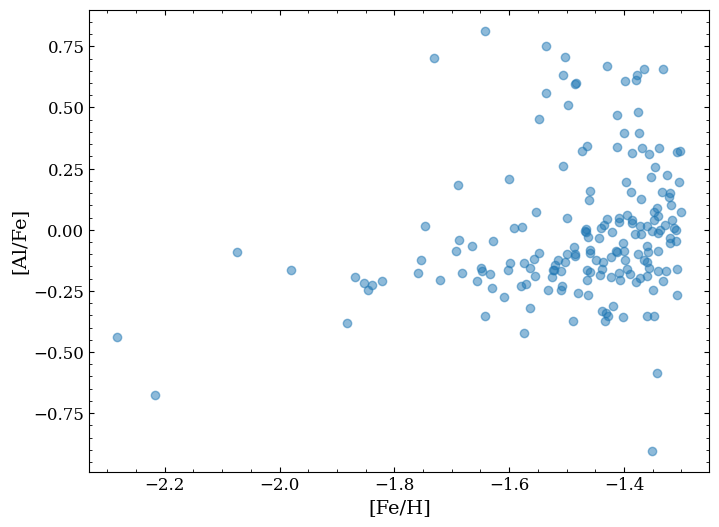

In [19]:
prodisk = galah_prodisk_abunds[['sobject_id', 'fe_h', 'al_fe', 'sc_fe']]


# plt.figure(figsize=(8, 6))
# plt.scatter(prodisk['fe_h'], prodisk['mg_fe'], label='Mg/Fe', alpha=0.5)
# plt.xlabel('[Fe/H]')
# plt.ylabel('[Mg/Fe]')


plt.figure(figsize=(8, 6))
plt.scatter(prodisk['fe_h'], prodisk['al_fe'], label='Al/Fe', alpha=0.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Al/Fe]')

# plt.figure(figsize=(8, 6))
# plt.scatter(prodisk['fe_h'], prodisk['sc_fe'], label='Sc/Fe', alpha=0.5)
# plt.xlabel('[Fe/H]')
# plt.ylabel('[Sc/Fe]')

Text(0, 0.5, '[Sc/Fe]')

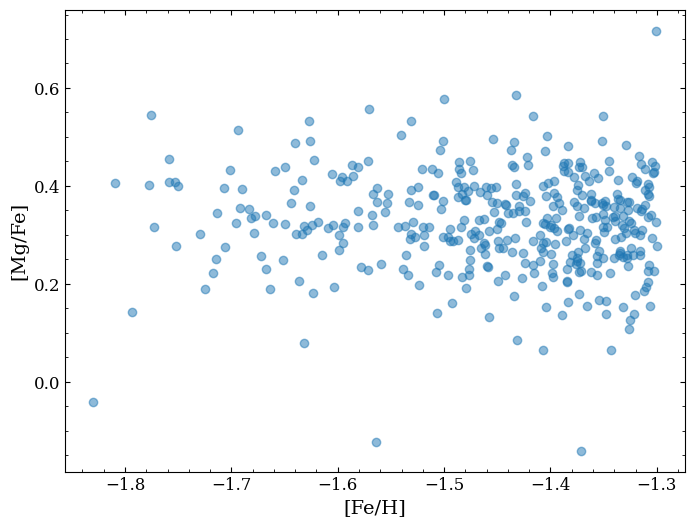

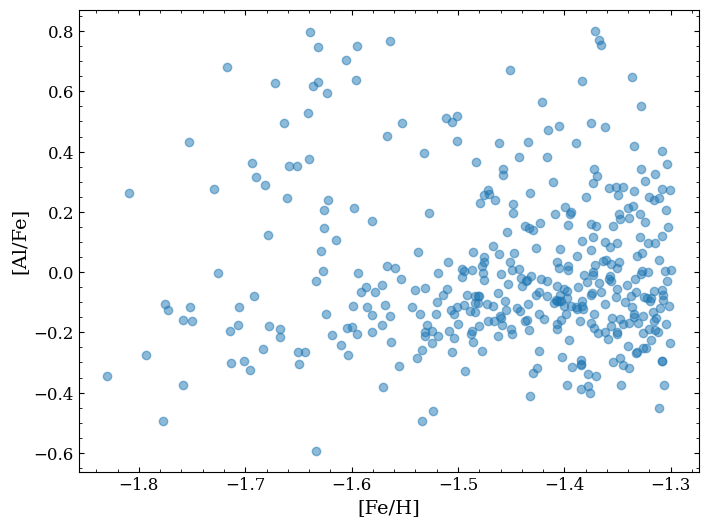

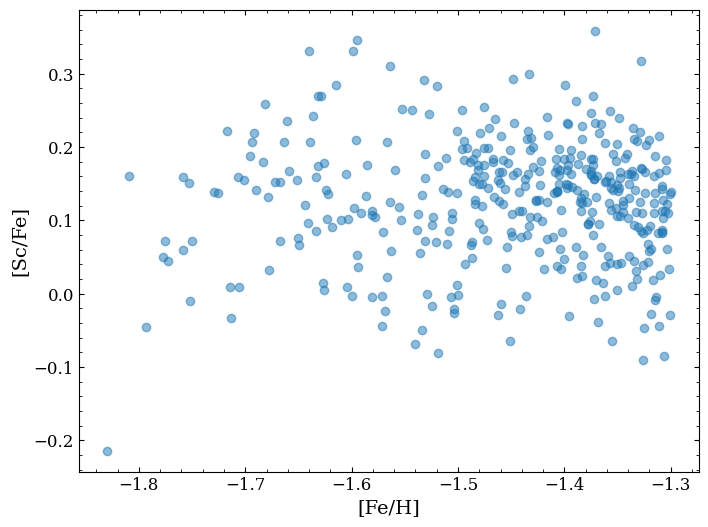

In [28]:
halo = galah_halo_abunds[['sobject_id', 'fe_h', 'mg_fe', 'al_fe', 'sc_fe']]


plt.figure(figsize=(8, 6))
plt.scatter(halo['fe_h'], halo['mg_fe'], label='Mg/Fe', alpha=0.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Mg/Fe]')


plt.figure(figsize=(8, 6))
plt.scatter(halo['fe_h'], halo['al_fe'], label='Al/Fe', alpha=0.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Al/Fe]')

plt.figure(figsize=(8, 6))
plt.scatter(halo['fe_h'], halo['sc_fe'], label='Sc/Fe', alpha=0.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Sc/Fe]')